# 01 — Exploratory analysis: the funding gap

**Design period only (2024-08-01 to 2026-06-30).** Phase 3 items 1 and 6 of `docs/plan.md`.
Every number comes from `src/analysis/gap_stats.py`; this notebook only calls it and displays the
results. The same tables are saved to `report/tables/eda_*.csv` and the charts to `report/figures/`.

Conventions: rates are hourly fractions in the panel and shown here as APR (hourly × 8760).
The gap is the known-at-t series, `f_hl_known − f_bn_known`; positive means Hyperliquid longs pay
more. Venue funding levels use the realised series. No trading rules are proposed here.

In [1]:
from IPython.display import Image, display
from src.analysis import gap_stats

res = gap_stats.run()          # loads the design-period panel, computes and saves everything
pct = "{:.1%}".format

## 1. Gap distribution per coin (APR)

Mean, median, standard deviation and tail percentiles of the hourly gap, plus the share of hours
with an absolute gap above 10%, 25% and 50% APR.

In [2]:
g = res["gap_summary"]
g.style.format({c: pct for c in g.columns if c != "hours"})

,hours,mean,median,std,p1,p5,p95,p99,share_abs_gt_10%,share_abs_gt_25%,share_abs_gt_50%
coin,,,,,,,,,,,
BTC,16767,5.8%,4.8%,12.8%,-21.0%,-10.3%,24.2%,55.1%,27.5%,5.3%,1.3%
ETH,16767,4.5%,3.9%,13.8%,-27.0%,-14.3%,23.2%,56.6%,28.7%,6.0%,1.5%
SOL,16767,5.2%,4.6%,24.0%,-37.4%,-20.2%,31.3%,64.9%,44.9%,10.2%,2.4%
kPEPE,16767,10.4%,3.8%,28.3%,-47.9%,-19.1%,57.8%,110.4%,45.6%,19.0%,7.1%
SUI,16767,4.0%,2.3%,19.0%,-45.1%,-22.8%,31.9%,72.2%,38.4%,11.4%,3.4%
WIF,16771,10.0%,1.1%,36.7%,-33.7%,-12.5%,50.3%,90.1%,40.2%,18.4%,5.4%
TIA,16771,9.6%,0.7%,30.5%,-47.1%,-26.3%,63.9%,118.6%,50.3%,24.6%,8.6%
DOGE,16767,6.6%,3.5%,20.9%,-29.2%,-13.6%,39.1%,86.6%,34.0%,9.2%,3.8%
WLD,16767,6.5%,1.9%,21.0%,-49.2%,-21.2%,41.4%,81.5%,40.2%,15.2%,4.6%


## 2. Funding level on each venue (APR)

Median and mean realised funding per venue. `median_daily_ratio` is the median HL/BN ratio of
daily means on days when both are positive (the BTC 1.87 in `report/data_quality.md`).
`ratio_of_means` is not meaningful where the Binance mean is near zero or negative.

In [3]:
v = res["venue_funding"]
v.style.format({**{c: pct for c in v.columns if c.endswith("_apr")},
                "ratio_of_means": "{:.2f}", "median_daily_ratio": "{:.2f}"})

,hl_median_apr,hl_mean_apr,bn_median_apr,bn_mean_apr,mean_diff_apr,ratio_of_means,median_daily_ratio,days_both_positive
coin,,,,,,,,
BTC,10.9%,10.6%,4.6%,4.8%,5.8%,2.22,1.87,546
ETH,10.9%,9.3%,4.9%,4.8%,4.5%,1.94,1.77,511
SOL,10.9%,6.2%,2.3%,1.1%,5.1%,5.76,2.10,373
kPEPE,10.9%,13.6%,8.9%,3.2%,10.4%,4.20,2.12,443
SUI,10.9%,7.0%,4.6%,3.0%,4.0%,2.33,1.58,417
WIF,10.9%,10.7%,10.9%,0.7%,10.0%,14.38,1.62,452
TIA,10.9%,1.0%,6.1%,-8.7%,9.6%,-0.11,1.55,323
DOGE,10.9%,11.4%,5.4%,4.7%,6.6%,2.39,1.98,496
WLD,10.9%,7.3%,7.5%,0.8%,6.5%,8.97,1.43,441


## 3. Structural baseline check

**Resting rates.** When the premium sits inside the interest clamp, funding equals the documented
interest baseline: 0.01% per 8h on both venues (0.00125% per hour; on Binance 0.01% x interval/8
per settlement), set in `config.yaml`. The *mechanical gap* is the gap when both venues rest; with
the same baseline on both venues it is 0. As a sanity check, the most frequent observed hourly rate
is reported per venue and `modal_differs_*` flags any coin where it is not the documented baseline
(see LIMITATIONS.md for flagged coins).

In [4]:
r = res["resting_rates"]
r.style.format({"hl_rest_per_hour": "{:.7f}", "bn_rest_per_hour": "{:.7f}",
                "hl_modal_per_hour": "{:.7f}", "bn_modal_per_hour": "{:.7f}",
                "hl_share_at_rest": pct, "bn_share_at_rest": pct, "mechanical_gap_apr": pct})

,hl_rest_per_hour,bn_rest_per_hour,hl_share_at_rest,bn_share_at_rest,mechanical_gap_apr,hl_modal_per_hour,bn_modal_per_hour,modal_differs_hl,modal_differs_bn
coin,,,,,,,,,
BTC,0.0000125,0.0000125,56.0%,17.8%,0.0%,0.0000125,0.0000125,False,False
ETH,0.0000125,0.0000125,51.0%,18.2%,0.0%,0.0000125,0.0000125,False,False
SOL,0.0000125,0.0000125,44.6%,18.9%,0.0%,0.0000125,0.0000125,False,False
kPEPE,0.0000125,0.0000125,56.5%,41.4%,0.0%,0.0000125,0.0000125,False,False
SUI,0.0000125,0.0000125,50.6%,25.4%,0.0%,0.0000125,0.0000125,False,False
WIF,0.0000125,0.0000125,63.6%,50.1%,0.0%,0.0000125,0.0000125,False,False
TIA,0.0000125,0.0000125,43.6%,38.2%,0.0%,0.0000125,0.0000125,False,False
DOGE,0.0000125,0.0000125,49.1%,25.3%,0.0%,0.0000125,0.0000125,False,False
WLD,0.0000125,0.0000125,58.5%,39.0%,0.0%,0.0000125,0.0000125,False,False


**Constant vs fluctuating part.** `slow` is the trailing 30-day mean of the hourly gap, `fast`
the deviation from it. `slow_var_share` is the share of gap variance the slow part accounts for;
`share_months_positive` the share of the 23 calendar months with a positive mean gap.

In [5]:
s = res["structural_baseline"]
s.style.format({**{c: pct for c in s.columns if c.endswith("_apr") or c.startswith("share")},
                "slow_var_share": pct, "months": "{:d}"})

,mean_gap_apr,mechanical_gap_apr,mean_gap_ex_mechanical_apr,std_slow_apr,std_fast_apr,slow_var_share,months,share_months_positive,share_hours_both_at_rest
coin,,,,,,,,,
BTC,5.8%,0.0%,5.8%,4.4%,12.5%,11.8%,23,100.0%,10.4%
ETH,4.5%,0.0%,4.5%,5.4%,13.3%,15.1%,23,87.0%,10.9%
SOL,5.2%,0.0%,5.2%,7.1%,23.6%,8.6%,23,78.3%,9.5%
kPEPE,10.4%,0.0%,10.4%,11.9%,26.7%,17.6%,23,87.0%,25.0%
SUI,4.0%,0.0%,4.0%,6.3%,18.4%,11.4%,23,69.6%,16.8%
WIF,10.0%,0.0%,10.0%,6.8%,37.1%,3.3%,23,95.7%,35.8%
TIA,9.6%,0.0%,9.6%,13.0%,27.8%,18.8%,23,78.3%,23.1%
DOGE,6.6%,0.0%,6.6%,9.2%,20.0%,18.7%,23,91.3%,14.4%
WLD,6.5%,0.0%,6.5%,6.9%,20.1%,11.2%,23,91.3%,28.1%


## 4. Charts

Gap over time for BTC and one mid-cap (WLD, fixed in `config.yaml` before these statistics were
computed: the median non-anchor coin by Aug–Oct 2024 Hyperliquid volume), on the same scale.

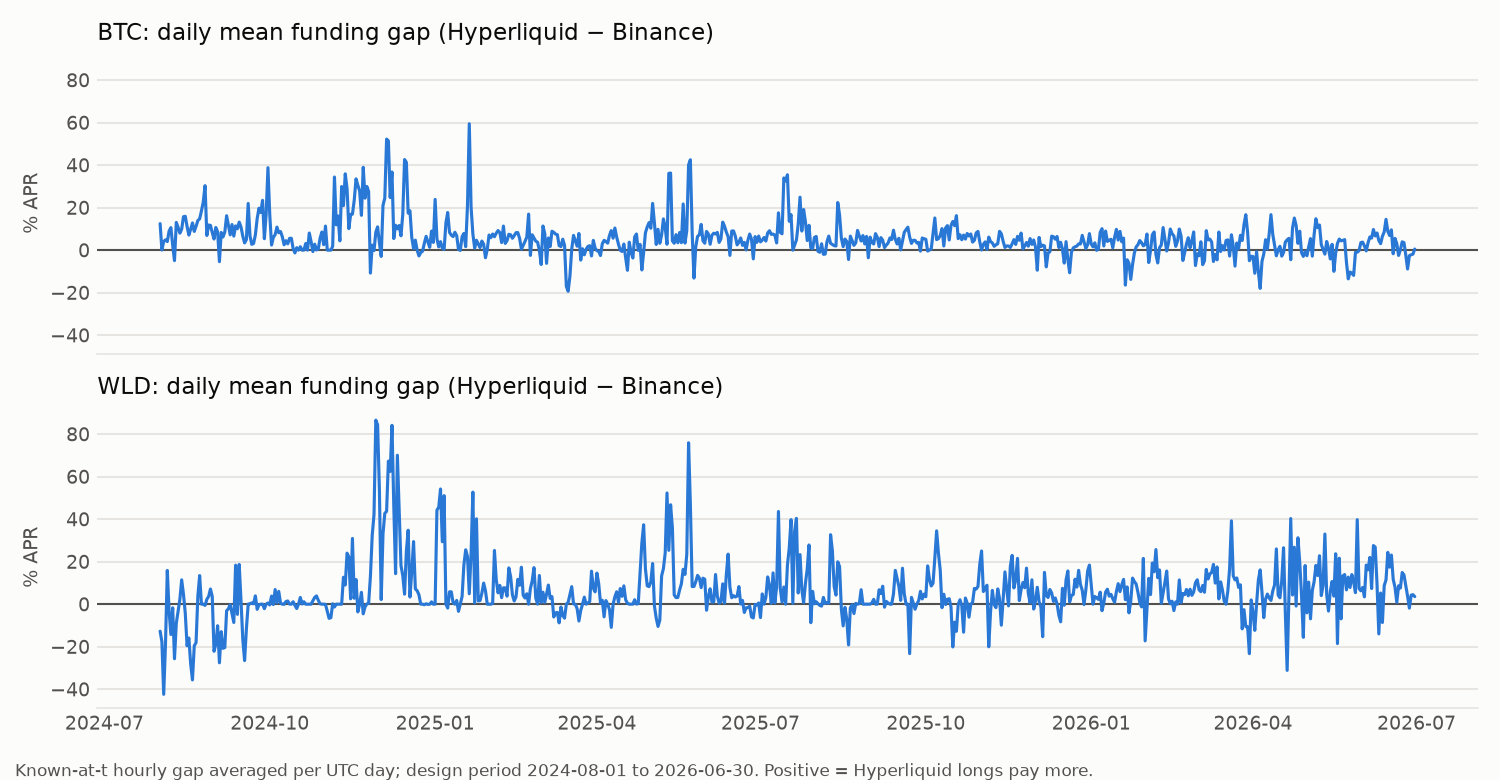

In [6]:
display(Image(filename=str(gap_stats.FIGURES / "eda_gap_over_time.png")))

Pooled histogram of the hourly gap across all 15 coins (log scale).

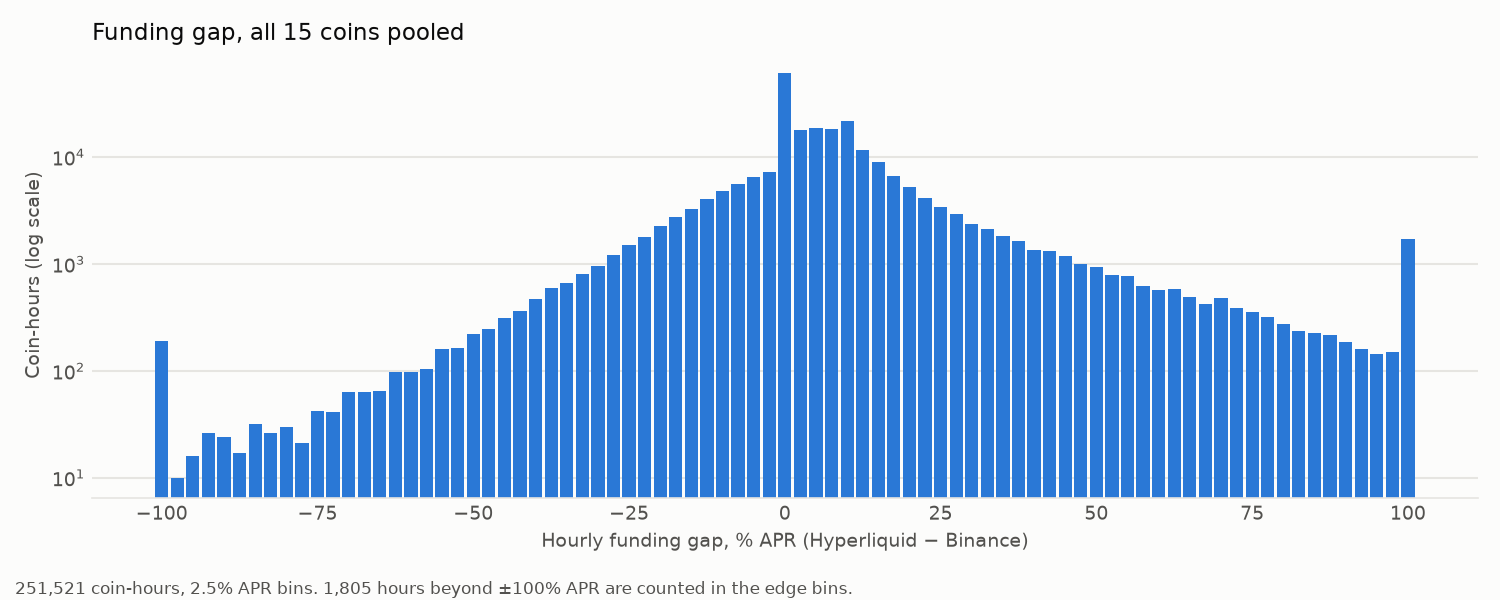

In [7]:
display(Image(filename=str(gap_stats.FIGURES / "eda_gap_histogram.png")))